In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
clmentbisaillon_fake_and_real_news_dataset_path = kagglehub.dataset_download('clmentbisaillon/fake-and-real-news-dataset')

print('Data source import complete.')


In [ ]:
!pip install transformers datasets accelerate shap wordcloud -q
!pip install -U transformers accelerate

In [ ]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import os
import shutil

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

import shap

In [ ]:
import pandas as pd
import re

fake = pd.read_csv("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/Fake.csv")
real = pd.read_csv("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/True.csv")

fake["label"] = 0
real["label"] = 1

df = pd.concat([fake, real]).reset_index(drop=True)

df["text"] = df["title"] + " " + df["text"]
df = df[["text", "label"]]

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", "", text)
    return text.strip()

df["text"] = df["text"].apply(clean_text)

df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

df = df.sample(8000, random_state=42).reset_index(drop=True)

print(df.shape)
df.head()

(8000, 2)


,text,label
0,iranian commander issued stark warning to iraq...,1
1,trump just got ripped apart after demanding cl...,0
2,turkish newspaper staff remanded in custody ov...,1
3,former illinois congressman requests to plead ...,1
4,white house not in saudi interest to destabili...,1


In [ ]:
print(len(set(train_texts).intersection(set(test_texts))))

0


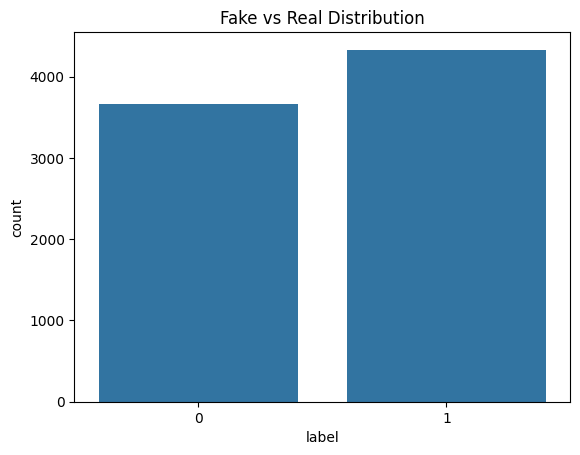

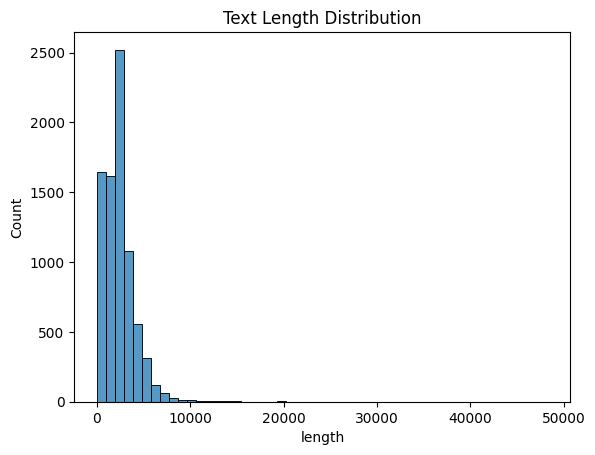

In [ ]:
sns.countplot(x="label", data=df)
plt.title("Fake vs Real Distribution")
plt.show()

df["length"] = df["text"].apply(len)

sns.histplot(df["length"], bins=50)
plt.title("Text Length Distribution")
plt.show()

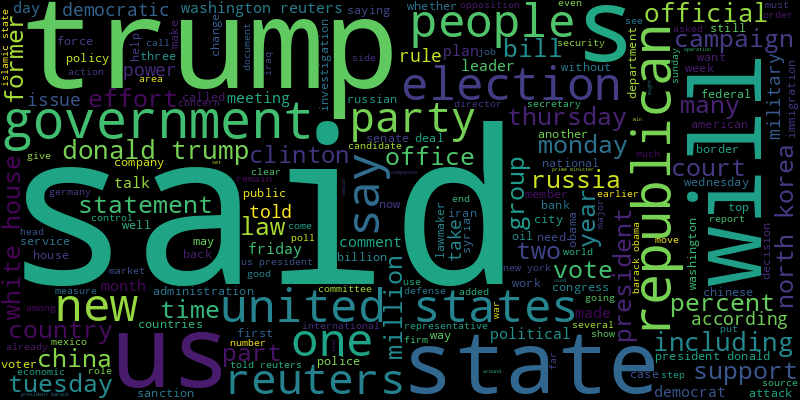

In [ ]:
fake_text = " ".join(df[df.label==0]["text"].sample(300))
real_text = " ".join(df[df.label==1]["text"].sample(300))

WordCloud(width=800, height=400).generate(fake_text).to_image()
WordCloud(width=800, height=400).generate(real_text).to_image()

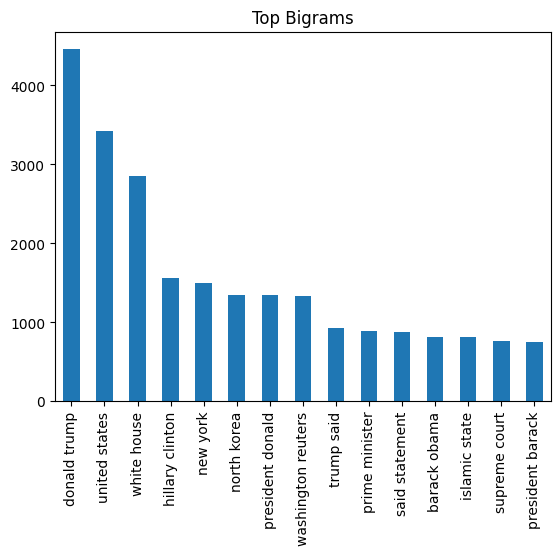

In [ ]:
vectorizer = CountVectorizer(ngram_range=(2,2), stop_words='english', max_features=15)
X = vectorizer.fit_transform(df["text"])

pd.Series(X.toarray().sum(axis=0), index=vectorizer.get_feature_names_out()).sort_values(ascending=False).plot(kind="bar")
plt.title("Top Bigrams")
plt.show()

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

groups = df["text"]

train_idx, test_idx = next(gss.split(df, df["label"], groups))

train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

train_texts = train_df["text"].tolist()
test_texts = test_df["text"].tolist()

train_labels = train_df["label"].tolist()
test_labels = test_df["label"].tolist()

In [ ]:
def tokenize_data(tokenizer, texts):
    return tokenizer(texts, truncation=True, padding=True, max_length=256)

class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

In [ ]:
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)

    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')
    acc = accuracy_score(labels, preds)

    return {"accuracy": acc, "f1": f1, "precision": precision, "recall": recall}

In [ ]:
def train_model(model_name):

    print(f"\nTraining {model_name}...\n")

    shutil.rmtree(f"./results_{model_name}", ignore_errors=True)

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    train_enc = tokenize_data(tokenizer, train_texts)
    test_enc = tokenize_data(tokenizer, test_texts)

    train_dataset = NewsDataset(train_enc, train_labels)
    test_dataset = NewsDataset(test_enc, test_labels)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

    args = TrainingArguments(
        output_dir=f"./results_{model_name}",
        learning_rate=3e-5,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=2,
        fp16=True,
        logging_steps=100,
        save_strategy="no",
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=test_dataset,
        compute_metrics=compute_metrics
    )

    trainer.train()
    return trainer, tokenizer

In [ ]:
trainer_bert, tokenizer_bert = train_model("bert-base-uncased")
results_bert = trainer_bert.evaluate()

print(results_bert)


Training bert-base-uncased...



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3

Step,Training Loss
100,0.308209
200,0.028404
300,0.028623
400,0.031590
500,0.000288
600,0.009414
700,0.000122
800,0.000379


Training Loss,Validation Loss,Step,Accuracy,F1,Precision,Recall
0.000379,0.018859,800,0.998125,0.998308,0.997745,0.998871


{'eval_loss': 0.018859069794416428, 'eval_accuracy': 0.998125, 'eval_f1': 0.9983079526226735, 'eval_precision': 0.9977452085682075, 'eval_recall': 0.9988713318284425}


In [ ]:
trainer_distil, tokenizer_distil = train_model("distilbert-base-uncased")
results_distil = trainer_distil.evaluate()


Training distilbert-base-uncased...



Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super(

Step,Training Loss
100,0.280373
200,0.014351
300,0.027226
400,0.018962
500,0.007658
600,0.007981
700,0.000455
800,0.010289


Training Loss,Validation Loss,Step,Accuracy,F1,Precision,Recall
0.010289,0.041265,800,0.997500,0.997743,0.997743,0.997743


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


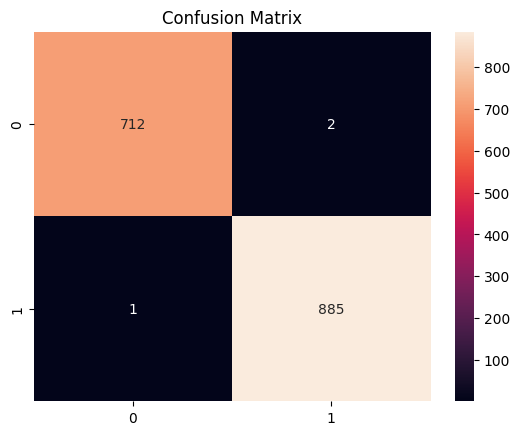

In [ ]:
preds = trainer_bert.predict(NewsDataset(
    tokenize_data(tokenizer_bert, test_texts),
    test_labels
))

y_pred = np.argmax(preds.predictions, axis=1)

cm = confusion_matrix(test_labels, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

In [ ]:
def predict(texts):
    if isinstance(texts, str):
        texts = [texts]

    texts = [str(t) for t in texts]

    inputs = tokenizer_bert(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=256
    )

    inputs = {k: v.to(trainer_bert.model.device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = trainer_bert.model(**inputs)

    return torch.softmax(outputs.logits, dim=1).cpu().numpy()

                         eval_accuracy   eval_f1  eval_precision  eval_recall
bert-base-uncased             0.999889  0.999883             1.0     0.999767
distilbert-base-uncased       1.000000  1.000000             1.0     1.000000


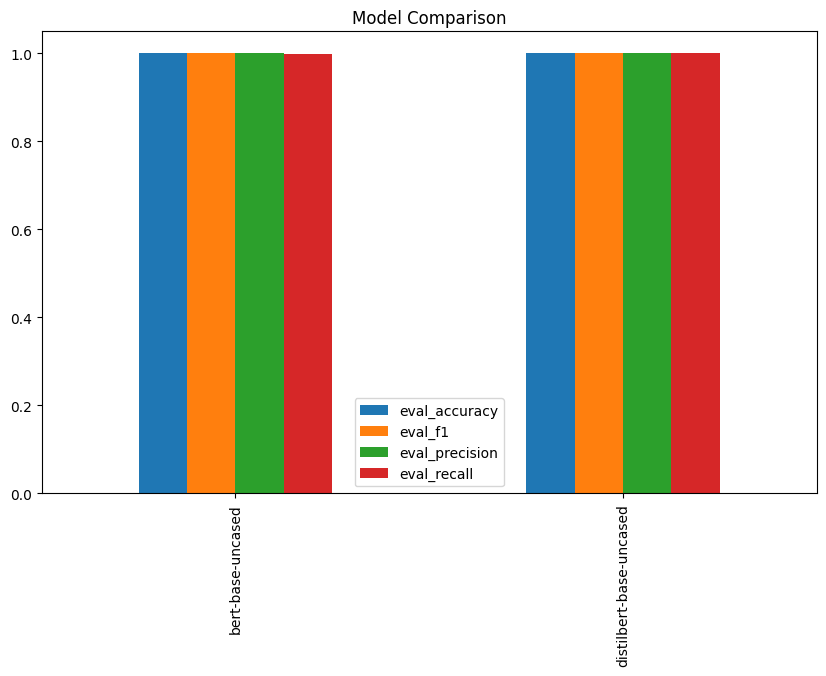

In [ ]:
results_df = pd.DataFrame(results).T
results_df = results_df[["eval_accuracy", "eval_f1", "eval_precision", "eval_recall"]]

print(results_df)

results_df.plot(kind="bar", figsize=(10,6))
plt.title("Model Comparison")
plt.show()

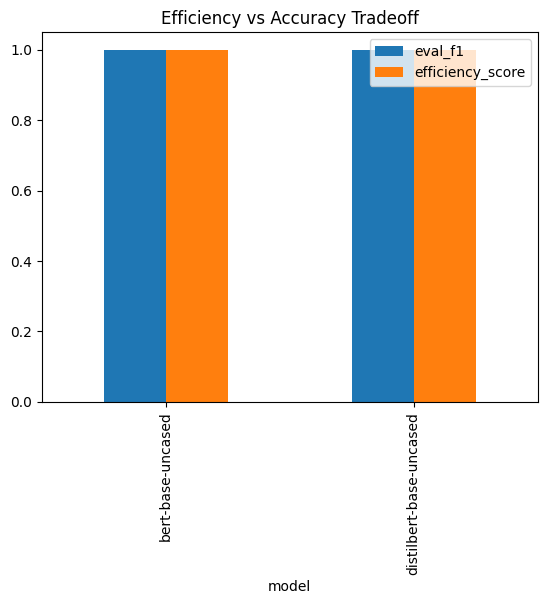

In [ ]:
results_df["model"] = results_df.index
results_df["efficiency_score"] = 1 / results_df["eval_f1"]

results_df.plot(x="model", y=["eval_f1", "efficiency_score"], kind="bar")
plt.title("Efficiency vs Accuracy Tradeoff")
plt.show()